In [1]:
import sys, time, math, numpy as np, matplotlib.pyplot as plt
# Ensure package path (relative to repo root) is available
sys.path.append('../../python')
from ptm_ice.ice_table_vectorized import compute_ice_depths_vectorized

# Grid and physical parameters
NX, NY = 100, 100  # 100 x 100 -> 10^4 elements
J0 = 3e-14          # vapor flux limit [kg m^-2 s^-1]
delta = 1e-4        # convergence tolerance [m]
l = 100e-6          # mean free path [m]
zs = 0.1            # thermal skin depth [m]
Q = 0.02            # geothermal flux [W m^-2]
k = 1e-3            # thermal conductivity [W m^-1 K^-1]
chunk_size = 5000   # process in two chunks for demonstration
dtype = np.float64  # working precision

# Generate smooth mean temperature field (Tavg) using combined sinusoids
x = np.linspace(0, 2 * np.pi, NX)
y = np.linspace(0, 2 * np.pi, NY)
X, Y = np.meshgrid(x, y)
# Base mean temperature ~100 K +/- variation
Tavg = 120 + 15 * np.sin(X) * np.cos(Y) + 5 * np.sin(2 * X)
# Ensure max temperature always exceeds mean by a positive margin
Tmax = Tavg + 5 + 20 * np.cos(X * 0.5) * np.sin(Y * 0.5)

# Sanity: guarantee Tmax >= Tavg everywhere
mask = Tmax < Tavg
if np.any(mask):
    Tmax[mask] = Tavg[mask] + 1.0

print(f'Grid shape: {Tavg.shape}, elements: {Tavg.size}')
print(f'Tavg range: {Tavg.min():.2f} K .. {Tavg.max():.2f} K')
print(f'Tmax range: {Tmax.min():.2f} K .. {Tmax.max():.2f} K')

Grid shape: (100, 100), elements: 10000
Tavg range: 102.58 K .. 137.42 K
Tmax range: 104.87 K .. 145.22 K


In [2]:
# Run vectorized solver
t0 = time.perf_counter()
depths, iters = compute_ice_depths_vectorized(Tavg, Tmax, J0, delta=delta, l=l, zs=zs, Q=Q, k=k, chunk_size=chunk_size, return_iterations=True, dtype=dtype)
t1 = time.perf_counter()
elapsed_ms = (t1 - t0) * 1e3

print(f'Solver elapsed: {elapsed_ms:.2f} ms')
print(f'Converged fraction: {np.mean(~np.isnan(depths)) * 100:.2f}%')
print(f'Depth stats (excluding NaN): min={np.nanmin(depths):.6f} m, max={np.nanmax(depths):.6f} m, mean={np.nanmean(depths):.6f} m')
print(f'Iterations (excluding unused): mean={np.mean(iters[iters>0]):.2f}, max={np.max(iters):d}')

Solver elapsed: 96.44 ms
Converged fraction: 88.24%
Depth stats (excluding NaN): min=0.000000 m, max=0.236671 m, mean=0.023183 m
Iterations (excluding unused): mean=26.18, max=200


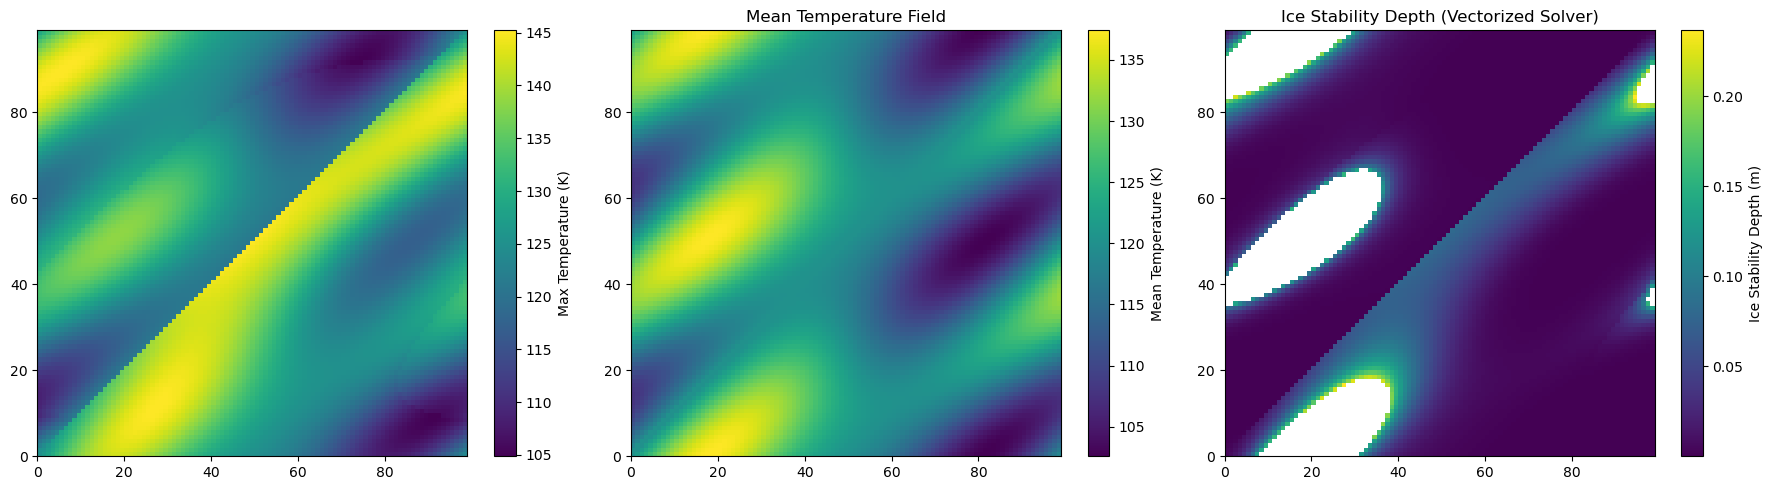

In [3]:
# Visualize temperature and depth fields
plt.figure(figsize=(18,5))
plt.subplot(1,3,1)
plt.pcolormesh(Tmax, shading='nearest')
plt.colorbar(label='Max Temperature (K)')
plt.subplot(1,3,2)
plt.pcolormesh(Tavg, shading='nearest')
plt.colorbar(label='Mean Temperature (K)')
plt.title('Mean Temperature Field')
plt.subplot(1,3,3)
plt.pcolormesh(depths, shading='nearest')
plt.colorbar(label='Ice Stability Depth (m)')
plt.title('Ice Stability Depth (Vectorized Solver)')
plt.tight_layout()

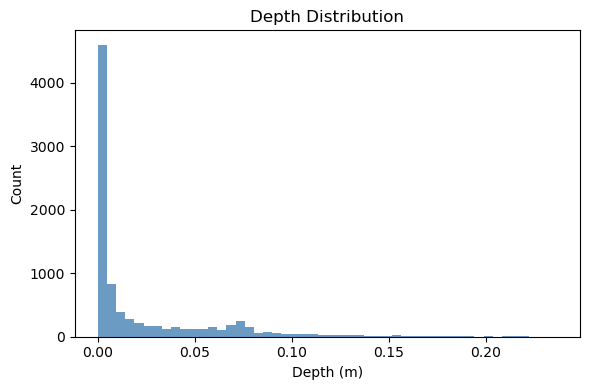

In [4]:
# Histogram of depths (excluding NaN)
valid = depths[~np.isnan(depths)]
plt.figure(figsize=(6,4))
plt.hist(valid, bins=50, color='steelblue', alpha=0.8)
plt.xlabel('Depth (m)')
plt.ylabel('Count')
plt.title('Depth Distribution')
plt.tight_layout()

In [5]:
# Consistency check: re-run without chunking and compare
depths_full, _ = compute_ice_depths_vectorized(Tavg, Tmax, J0, delta=delta, l=l, zs=zs, Q=Q, k=k, chunk_size=None, return_iterations=False, dtype=dtype)
diff = np.nanmax(np.abs(depths - depths_full))
print(f'Max absolute difference chunked vs full: {diff:.3e} m')
assert diff < 1e-9, 'Chunking altered results beyond tolerance'

Max absolute difference chunked vs full: 0.000e+00 m


### Next Steps
- Add Numba JIT parallel backend for further speedup.
- Integrate with PTM3D face temperature outputs (HDF5 or VTU).
- Introduce memory-mapped IO for >10^7 faces.
- C++/pybind11 implementation for maximum throughput.

## C++ Integration Complete

The ice table solver has been successfully implemented in C++ and integrated into PTM3D:

### Implementation Details
- **Module**: `src/cpp/ice/ice_table.{h,cpp}`
- **Namespace**: `ice::`
- **Primary API**: `ice::computeIceDepths(Tavg, Tmax, J0, ...)`
- **Parallelization**: OpenMP-enabled for multi-threaded execution
- **Physical constants**: Match Python implementation exactly

### Integration in `ptm_thermal_sim`
After computing temperature statistics (mean, max, min), the simulator now:
1. Calls `ice::computeIceDepths(temp_stats.avg, temp_stats.max, J0, ...)`
2. Exports ice depth as `statistics/ice_depth_avg.bin`
3. Reports ice depth statistics (valid count, mean, range)

### Output Files

#### Binary Format (from C++ simulation)
- `statistics/temperature_avg.bin` - mean temperature [K]
- `statistics/temperature_max.bin` - max temperature [K]
- `statistics/temperature_min.bin` - min temperature [K]
- `statistics/ice_depth_avg.bin` - **ice stability depth [m]**

#### VTU/PVD Format (from Python converter)
After running the VTK converter (`vtk_converter_optimized.py`), you get:
- `statistics_avg.vtu` - all mean values (temperature, illumination, etc.)
- `statistics_max.vtu` - all max values
- `statistics_min.vtu` - all min values
- `statistics.pvd` - ParaView collection file linking these three VTU files

Note: `ice_depth` is included as a CellData array in all three VTU files and remains constant across the avg/max/min timesteps.

### Usage

**Step 1: Run thermal simulation** (generates binary files including ice depths):
```bash
ptm_thermal_sim --config your_config.yaml
```

**Step 2: Convert to VTU/PVD for ParaView** (includes ice depths automatically):
```bash
cd output/your_simulation
python /path/to/vtk_converter_optimized.py . vtk_output
```

**Step 3: Visualize in ParaView**:
- Open `vtk_output/statistics.pvd`
- `ice_depth` appears as CellData and is constant across avg/max/min
- Use the time slider to switch between avg/max/min views

### Physical Parameters
Default ice depth solver parameters (matching Python implementation):
- J₀ = 3×10⁻¹⁴ kg m⁻² s⁻¹ (vapor flux limit)
- δ = 10⁻⁴ m (convergence tolerance)
- l = 100 μm (mean free path)
- zₛ = 0.1 m (thermal skin depth)
- Q = 0.02 W m⁻² (geothermal flux)
- k = 10⁻³ W m⁻¹ K⁻¹ (thermal conductivity)